# 03 · 若依拔高原理篇（AI+若依）


## 本章来源与阅读路线

本篇依据百度网盘 **`我的资源/PPT(2)/04-拔高原理篇.pptx`**，共 94 页。第 3—86 页是技术内容，第 87—94 页是结课页。本篇对应用户指定的第三篇，源课件文件名前缀仍为 `04`。

课件预览：[拔高原理篇](https://pan.baidu.com/pfile/docview?path=%2F%E6%88%91%E7%9A%84%E8%B5%84%E6%BA%90%2FPPT(2)%2F04-%E6%8B%94%E9%AB%98%E5%8E%9F%E7%90%86%E7%AF%87.pptx&fsid=580830453378223&size=4693641&view_from=personal_file&md5=d09fa5bdch5d0c32291a987a34bd1fba&share=0&client=web&scene=main)。

六条主线分别回答：代码怎样生成、用户怎样获得权限、后台任务怎样异步执行、日志怎样自动记录、任务怎样动态调度、查询怎样限制数据范围。

| 课件主题 | 页码 | 阅读重点 |
|---|---|---|
| 代码生成器 | 3—26 | 数据库元信息、生成配置、Velocity、模板扩展 |
| RBAC 权限控制 | 27—47 | 登录、用户角色/权限、菜单路由、接口授权 |
| 异步任务管理器 | 48—52 | 任务工厂、任务管理器、线程池 |
| 操作日志 | 53—57 | `@Log`、AOP、异步落库 |
| 定时任务 | 58—73 | Quartz API、任务生命周期、共享数据库集群 |
| 数据权限 | 74—86 | 五种范围、`@DataScope`、SQL 过滤、登录日志改造 |

本文的“**课件方案**”来自 PPT 文字和截图；“**整理示例**”用于还原机制，类包名和依赖版本应以工程为准；“**补充/改进**”用于说明实现边界。示例默认 Java 11。课件的 Spring Security 使用 `WebSecurityConfigurerAdapter` 和 `@EnableGlobalMethodSecurity`，属于旧版配置方式；升级版本时需调整 API，不能混用新旧配置。


## 代码生成器的本质：元信息、配置和模板

重复编写实体、Mapper、Service、Controller 和前端页面会消耗大量时间。生成器把这些稳定结构交给模板，把表名、字段、业务名称等变化部分放进上下文。

```text
数据库表与字段元信息
        ↓ 导入、初始化、人工编辑
gen_table + gen_table_column
        ↓ 生成上下文
Velocity 模板
        ↓ 渲染
Java / Mapper XML / Vue / API JS / 菜单 SQL
```

**课件方案**：导入表结构后支持预览、编辑、删除、同步，以及生成前后端代码。生成器自身的配置表与真正的业务表用途不同：从生成器列表删除配置，通常只删除生成元信息，业务数据库表应另外管理。

这里的“元信息”是描述数据库表的数据，例如字段类型、注释、是否主键。生成器据此转换 Java 类型和页面组件，但事务、跨表校验、复杂权限仍需要业务代码完成。


## 生成器的两张配置表

同一张业务表可能需要不同页面和查询方式，因此不能只读取数据库 DDL，还要保存生成选项。

| 表 | 主要字段 | 用途 |
|---|---|---|
| `gen_table` | `table_id`、`table_name`、`table_comment`、`class_name` | 标识业务表及生成实体 |
| `gen_table` | `tpl_category`、`tpl_web_type`、`package_name`、`module_name`、`business_name` | 选择模板、前端类型、包路径和模块 |
| `gen_table` | `sub_table_name`、`sub_table_fk_name`、`options` | 主子表或树表扩展配置 |
| `gen_table` | `gen_type`、`gen_path`、`function_name`、`function_author` | 输出方式、路径、功能名称和作者 |
| `gen_table_column` | `column_id`、`table_id`、`column_name`、`column_type`、`column_comment` | 记录表字段，`table_id` 关联生成业务表 |
| `gen_table_column` | `java_type`、`java_field`、`is_pk`、`is_increment` | Java 映射、主键和自增信息 |
| `gen_table_column` | `is_insert`、`is_edit`、`is_list`、`is_query`、`is_required` | 决定新增、编辑、列表、查询、必填行为 |
| `gen_table_column` | `query_type`、`html_type`、`dict_type`、`sort` | 查询条件、控件、字典和排序 |

例如状态字段在数据库中是字符串，生成配置可以将其标为下拉框并绑定数据字典。表结构未变化，生成页面却会变化，这正是生成配置存在的原因。


## 生成器源码目录与调用入口

定位源码时先沿着页面、API、Controller、Service、Mapper、模板的顺序走。

```text
dkd-generator/
└─ src/main/
   ├─ java/com/dkd/generator/
   │  ├─ config/       生成配置
   │  ├─ controller/   GenController
   │  ├─ domain/       表、字段的元信息对象
   │  ├─ mapper/       元信息查询和配置持久化
   │  ├─ service/      导入、同步、预览、生成
   │  └─ util/         Velocity 初始化与上下文工具
   └─ resources/
      ├─ mapper/generator/
      ├─ vm/           java、xml、js、vue、sql 模板
      └─ generator.yml
```

前端包括 `src/api/tool/gen.js` 和 `src/views/tool/gen/` 下的 `index.vue`、`importTable.vue`、`basicInfoForm.vue`、`editTable.vue`、`genInfoForm.vue`。课件部分页简写为 `@/views/tool/index.vue`，以目录截图中的 `tool/gen` 层级及实际项目路径为准。

排查“某个字段为什么没有出现在页面”时，先看生成配置，再看上下文和对应模板分支，最后检查重新生成的文件是否导入正确位置。


## 查询可导入表：information_schema

生成器不能把自己的配置表和 Quartz 表再次当成普通业务表导入。课件的筛选包括当前数据库、排除 `qrtz_`/`gen_` 开头的表、排除已进入 `gen_table` 的表。

`information_schema` 是 MySQL 保存库、表、字段等元信息的系统数据库。**整理示例**：

```sql
SELECT table_name, table_comment
FROM information_schema.tables
WHERE table_schema = DATABASE()
  AND table_name NOT LIKE 'qrtz\\_%'
  AND table_name NOT LIKE 'gen\\_%'
  AND table_name NOT IN (SELECT table_name FROM gen_table);
```

`_` 在 `LIKE` 中表示任意单个字符。示例按 MySQL 常用的反斜杠转义方式表达字面下划线，执行时需核对 SQL 模式及 XML 中的写法。数据库名、表名筛选由服务端限制，不接收任意 SQL 文本。


## 导入表结构：初始化后再持久化

点击导入并选择表后，生成器将数据库结构转换为自己的配置对象。

```text
查询选中表的元信息
  → 初始化类名、业务名、包名等默认配置
  → 写入 gen_table，得到 table_id
  → 查询该表所有字段
  → 初始化 Java 类型、属性名、页面/查询选项
  → 每个字段携带 table_id 写入 gen_table_column
```

表配置与字段配置应整体成功，避免只导入一半。导入后仍需人工确认名称、字典、查询方式和模板类别。

**补充/改进**：同步表结构用于对齐增删字段及类型变化；同步后要复查人工设置。重新生成可能覆盖手工修改，业务增强应使用明确的扩展方式或先审查差异。


## 生成代码：上下文渲染与 ZIP 输出

**课件流程**：查询业务表和字段 → 初始化 Velocity 引擎 → 设置模板变量 → 获取模板列表 → 逐个渲染模板 → 将结果写入 ZIP → 返回客户端。

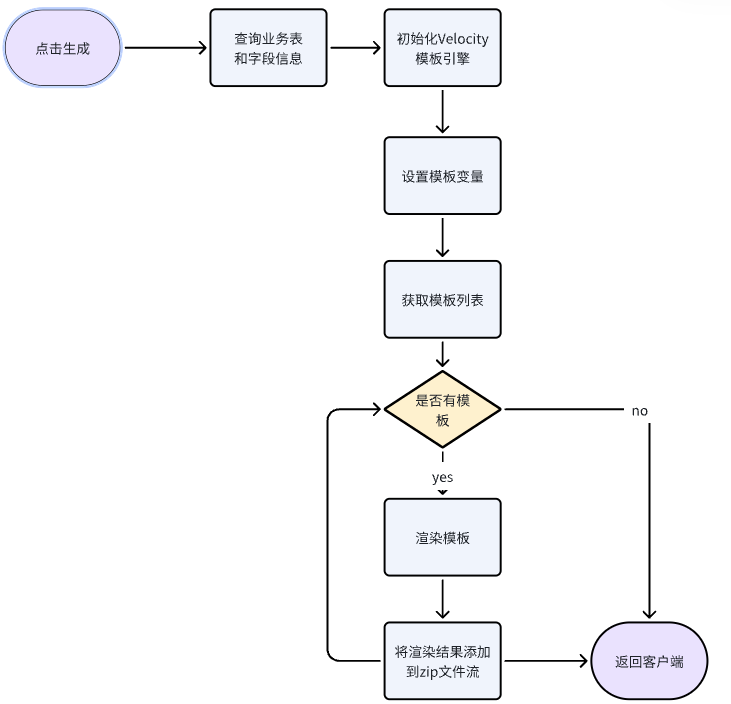

**整理示例**：

```java
// 机制片段，辅助方法由生成器提供
GenTable table = loadTableAndColumns(tableId);
VelocityContext context = buildContext(table);
for (String templateName : selectTemplates(table)) {
    Template template = Velocity.getTemplate(templateName, "UTF-8");
    StringWriter writer = new StringWriter();
    template.merge(context, writer);
    writeZipEntry(outputPath(templateName, table), writer.toString());
}
```

生成上下文通常包括类名、包路径、字段列表、主键和功能说明；输出路径决定 Java 文件、XML、页面分别放在哪里。模板中的类名正确，但输出文件名错误，同样会造成编译失败。


## generator.yml 的默认生成配置

课件第 13 页给出的示例：

```yaml
gen:
  author: itheima
  packageName: com.dkd.manage
  autoRemovePre: true
  tablePrefix: sys_,tb_
```

| 配置 | 作用 |
|---|---|
| `author` | 默认作者信息 |
| `packageName` | 默认生成包路径，需匹配业务模块 |
| `autoRemovePre` | 是否在生成类名时移除表前缀 |
| `tablePrefix` | 需要移除的前缀，多个用逗号分隔 |

配置影响后续初始化的默认值。已导入的表保存着自己的生成信息，修改 YAML 后仍要检查编辑页，不能假定历史记录全部随之更新。


## Velocity 模板引擎与快速入门

Velocity 通过模板语法读取 Java 对象，将固定文本与变化数据合并。它可生成 HTML、代码和静态页面；模板不负责判断业务需求是否合理。

课件示例准备 HTML 模板，放入 `message`，再输出 `index.html`。**整理示例，Java 11**：

```java
VelocityInitializer.initVelocity(); // 若依工程提供的初始化工具
VelocityContext context = new VelocityContext();
context.put("message", "加油同学！");
Template template = Velocity.getTemplate("vms/index.html.vm", "UTF-8");
try (Writer writer = Files.newBufferedWriter(
        Paths.get("index.html"), StandardCharsets.UTF_8)) {
    template.merge(context, writer);
}
```

模板正文：

```html
<meta charset="UTF-8">
<h3>心怀梦想，坚持不懈。${message}</h3>
```

需要导入 `java.io.Writer`、`java.nio.file.Files/Paths`、`java.nio.charset.StandardCharsets` 以及 Velocity 类，并配置模板加载路径。课件使用 `FileWriter`，整理示例显式指定 UTF-8、用 try-with-resources 关闭资源。


## Velocity 基础语法：变量、循环与条件

变量用 `$name` 或 `${name}` 读取，字符串与变量紧邻时使用花括号避免名称歧义。

```velocity
## 定义变量，双井号是单行注释
#set($name = "velocity")
${name}

#set($list = ["春", "夏", "秋", "冬"])
#foreach($item in $list)
  序号 ${foreach.count}：${item}
#end

#set($score = 80)
#if($score >= 80)
  优秀
#elseif($score >= 60)
  及格
#else
  不及格
#end
```

`foreach.count` 从 1 开始，`foreach.index` 从 0 开始。模板可访问对象属性，如 `$column.javaField`，常用于逐字段生成代码。

**课件边界**：第 21 页用 `#if($obj)` 说明对象判断。这是 Velocity 的真值判断，不能普遍等同“非 null”：布尔 false、空字符串/集合等的行为还与引擎版本和空值检查配置有关。业务需要精确区分“存在”和“有效”时，应传入明确的布尔变量。


## Lombok 集成：修改 domain 模板

为了让以后生成的所有实体自动减少样板代码，课件修改 `vm/java/domain.java.vm`，而不是每生成一张表再手工删 getter/setter。

课件的目标实体包含：

```java
@Data
@NoArgsConstructor
@AllArgsConstructor
@Builder
public class Order extends BaseEntity {
    private Long id;
    private String orderNo;
}
```

| 模板改动 | 工程配套 |
|---|---|
| 加入 Lombok import 和注解 | 业务模块能解析 Lombok 依赖 |
| 去除手工 getter/setter/toString 生成段 | 编译时启用注解处理 |
| 保留字段上的 Excel、时间格式等注解 | 不丢失若依框架映射能力 |

**补充/改进**：实体继承 `BaseEntity` 时，应按需要配置 `@EqualsAndHashCode(callSuper = true)`、`@ToString(callSuper = true)`，而不是盲目忽略或包含父类字段。普通 `@Builder` 不自动覆盖父类字段；确需构建继承字段时，评估 `@SuperBuilder` 的整个继承链。生成后至少编译一张样例表。


## Swagger 集成：修改 Controller 模板

课件第 26 页修改 `controller.java.vm`，让生成接口自带文档。

```java
@Api(tags = "订单管理Controller")
public class OrderController extends BaseController {
    @ApiOperation("查询订单管理列表")
    public TableDataInfo list(Order order) {
        // 保留分页、权限检查和业务调用
        return getDataTable(orderService.selectOrderList(order));
    }
}
```

这是与课件一致的 Swagger 2 注解风格（`io.swagger.annotations`）。项目采用 OpenAPI 3 时应改用相应的 `@Tag`、`@Operation`，并匹配文档依赖。

**怎么用**：类级说明由功能名称渲染，方法级说明按查询、新增、修改、删除生成。文档增强只改变说明，列表仍应返回分页对象，不能因课件演示片段省略权限、`startPage()` 或真实返回类型。


## RBAC、认证和授权

用户通过登录并不意味着能调用所有接口。安全系统需要分别回答“你是谁”和“你能做什么”。

| 概念 | 回答的问题 | 若依中的体现 |
|---|---|---|
| 认证 Authentication | 你是谁，身份是否可信 | 验证账号、密码、验证码；恢复登录状态 |
| 授权 Authorization | 你是否能执行这个动作 | 菜单权限、角色判断、`@PreAuthorize` |
| RBAC | 如何管理授权关系 | 用户关联角色，角色关联菜单/权限 |
| 数据权限 | 允许看哪些记录 | 角色的数据范围、`@DataScope` |

Spring Security 提供认证和授权机制。若依把用户、角色、菜单的数据库关系与它结合，用权限字符串如 `manage:order:list` 表示具体操作。

**面试提示**：功能权限决定能不能进“订单查询”接口，数据权限决定接口返回全部订单、本部门订单还是本人订单。两层都需要服务端执行。


## Spring Security 配置与版本边界

课件的 `SecurityConfig` 位于 `dkd-framework` 的 `config` 目录，截图展示：

```java
@EnableGlobalMethodSecurity(prePostEnabled = true, securedEnabled = true)
public class SecurityConfig extends WebSecurityConfigurerAdapter {
    @Autowired
    private UserDetailsService userDetailsService;
    // 其他配置以工程源码为准
}
```

配置类负责认证来源、请求授权、会话策略和安全过滤器。其中 `UserDetailsService` 负责加载用户，密码编码器负责校验密码，方法安全开关使 `@PreAuthorize` 生效。

**版本说明**：`WebSecurityConfigurerAdapter` 在 Spring Security 5.7 被弃用，在 6 中移除。若迁移到 Spring Boot 3/Security 6，通常使用 `SecurityFilterChain` Bean 和 `@EnableMethodSecurity`，还需升级到 Java 17+；本文的 Java 11 课件工程不能直接套用这套新依赖。


## 用户登录：校验、认证、日志与 Token

**课件链路**：`login.vue` 发起请求，由 `SysLoginController` 进入登录服务。

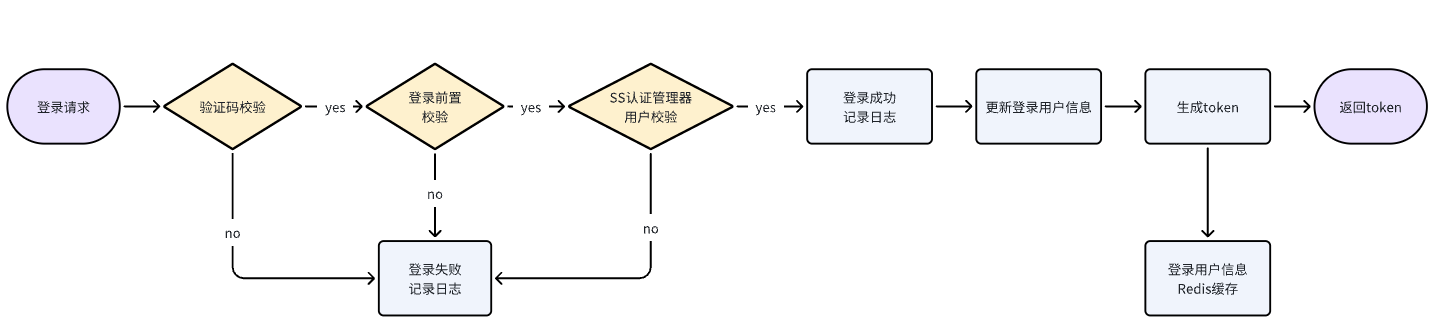

```text
验证码校验 → 登录前置校验 → Spring Security 认证管理器校验
           → 登录成功日志 → 更新登录信息 → 生成 Token → 返回
                         ↘ 登录用户信息保存到 Redis
```

前置检查用于过滤空输入、长度等不合法条件；认证管理器加载用户并校验密码；失败分支同样要记登录日志。Token 是后续请求的身份凭据，前端通常通过请求头携带它。

**补充/改进**：课件的 Token 与 Redis 登录对象配合使用，服务端通过令牌标识恢复用户权限和有效期。不能把它理解成“任何 JWT 都可以永久离线验证，完全不需要服务端状态”。后续请求仍要检查令牌有效性和登录对象是否存在。


## 获取角色和权限：getInfo 与按钮指令

登录后的前端路由守卫 `permission.js` 获取当前用户信息。课件流程先取登录用户，再查询角色和权限：管理员返回 `admin` 角色和 `*:*:*` 权限，普通用户按用户/角色关联查询。

前端将 `roles`、`permissions` 存入状态管理，用指令控制按钮：

```vue
<el-button v-hasPermi="['system:user:add']">新增用户</el-button>
<el-button v-hasPermi="['system:user:add', 'system:user:edit']">
  具备其中一个权限即可显示
</el-button>
<el-button v-hasRole="['admin']">管理员操作</el-button>
```

`v-hasPermi` 检查权限字符串，`v-hasRole` 检查角色标识；它们位于 `directive/permission/`，不能相互代替。

**正反例**：按钮隐藏且接口受 `@PreAuthorize` 保护，才是完整的功能授权；只有按钮隐藏，用户仍可能直接发 HTTP 请求调用接口。


## 动态菜单路由：菜单树如何变成页面

不同角色的导航应体现实际可访问功能。课件由当前用户 ID 查询可访问菜单，管理员取全部菜单，再构建菜单树和前端路由数据。

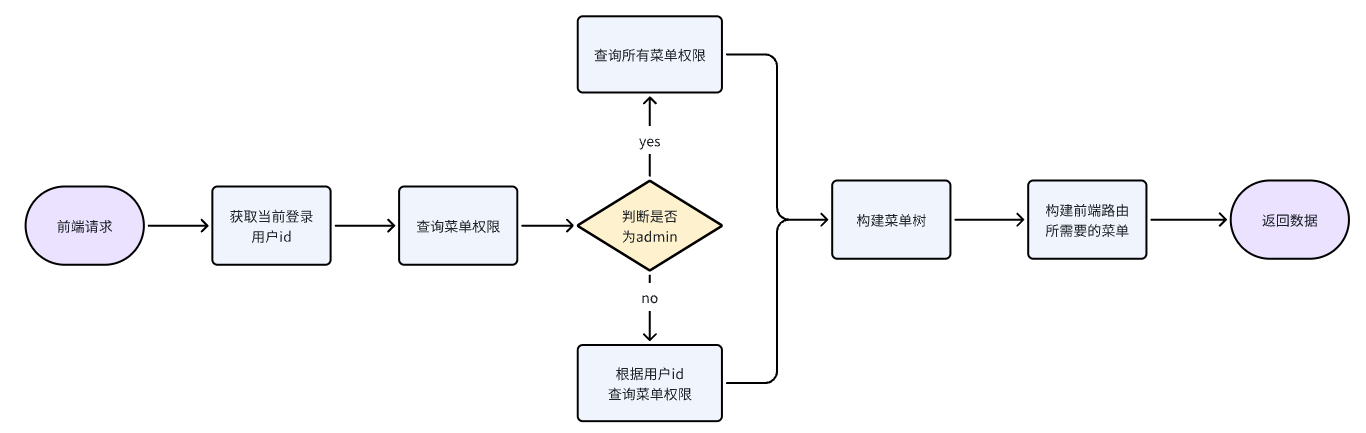

**页面过程**：前端取得路由数据，映射组件并注册路由；首页加载 `layout/index.vue`，侧边栏 `layout/components/Sidebar/index.vue` 遍历菜单；点击菜单后按 `path` 导航，在 `<app-main />` 中展示对应视图。

| 位置 | 主要职责 |
|---|---|
| `permission.js` | 登录检查、触发获取用户和动态路由 |
| `router/index.js` / 路由状态模块 | 维护静态及动态路由、加载组件 |
| `Sidebar` | 展示菜单 |
| `AppMain` | 展示当前路由视图 |

拿不到菜单时先检查角色菜单关联和后端路由响应，再检查前端组件路径，避免把数据库授权问题误判成 Vue 页面问题。


## @PreAuthorize 与 PermissionService

接口调用前必须检查服务端权限，若依借助 Spring Security 的方法安全与自定义权限服务实现。

```java
@PreAuthorize("@ss.hasPermi('manage:order:list')")
@GetMapping("/list")
public TableDataInfo list(Order order) {
    startPage();
    return getDataTable(orderService.selectOrderList(order));
}
```

`@ss` 引用名为 `ss` 的 `PermissionService` Bean，`hasPermi` 是该服务的方法，字符串是接口所需权限。注解表达式由 Spring 安全机制执行，不是 Java 普通方法调用语法。

| 方法 | 判断 |
|---|---|
| `hasPermi(String)` / `lacksPermi(String)` | 拥有/不拥有一个权限 |
| `hasAnyPermi(String)` | 拥有逗号分隔权限中的任意一个 |
| `hasRole(String)` / `lacksRole(String)` | 拥有/不拥有一个角色 |
| `hasAnyRoles(String)` | 拥有逗号分隔角色中的任意一个 |

前端指令通常接收数组，而这些后端“任意一个”方法在课件中接收逗号分隔字符串，不能直接照搬参数形式。


## @Anonymous：公开接口的边界

部分接口必须允许未登录访问，课件提供若依自定义注解 `@Anonymous`，可放在 Controller 类或方法上。框架收集相应路径并在请求安全规则中放行。

```java
// 整理示例：限定在确需公开的方法上
@Anonymous
@GetMapping("/public/status")
public AjaxResult publicStatus() {
    return AjaxResult.success("服务正常");
}
```

请求过滤层放行与方法级授权是两层机制。公开方法若还保留 `@PreAuthorize`，仍可能在方法层被拦截；课件因此提示移除该方法原有权限注解。

**补充/改进**：只对最小接口开放，不把含员工信息或后台管理操作的整个 Controller 标为匿名。公开不等于免除参数校验、限流和敏感字段筛选。


## 异步任务管理器：主线程只等待必要步骤

登录时若顺序执行认证、写日志、发送短信，响应时间会叠加。日志等无需即时返回结果的操作可交给后台线程池，主请求完成必要工作后返回。

| 执行方式 | 课件的示意耗时 | 影响 |
|---|---|---|
| 同步：认证、日志、短信依次执行 | 各 50 ms，共约 150 ms | 后续步骤拖慢主响应 |
| 异步：认证后提交日志/短信任务 | 主路径约 50 ms 加提交开销 | 后台任务继续执行 |

第 51 页的 `50S` 是示意图中的单位笔误，按前后页语境应为 `50 ms`。这些数字只用于解释机制，不是压测结果。

**适用场景**：记录登录日志、非关键通知。**不适用场景**：必须成功才能完成的扣款、权限变更或事务主数据写入，不能简单“提交线程池后就返回成功”。


## AsyncFactory、AsyncManager 与线程池

**课件方案**：工厂构造任务，管理器提交任务，Spring 容器提供线程池和日志 Service。

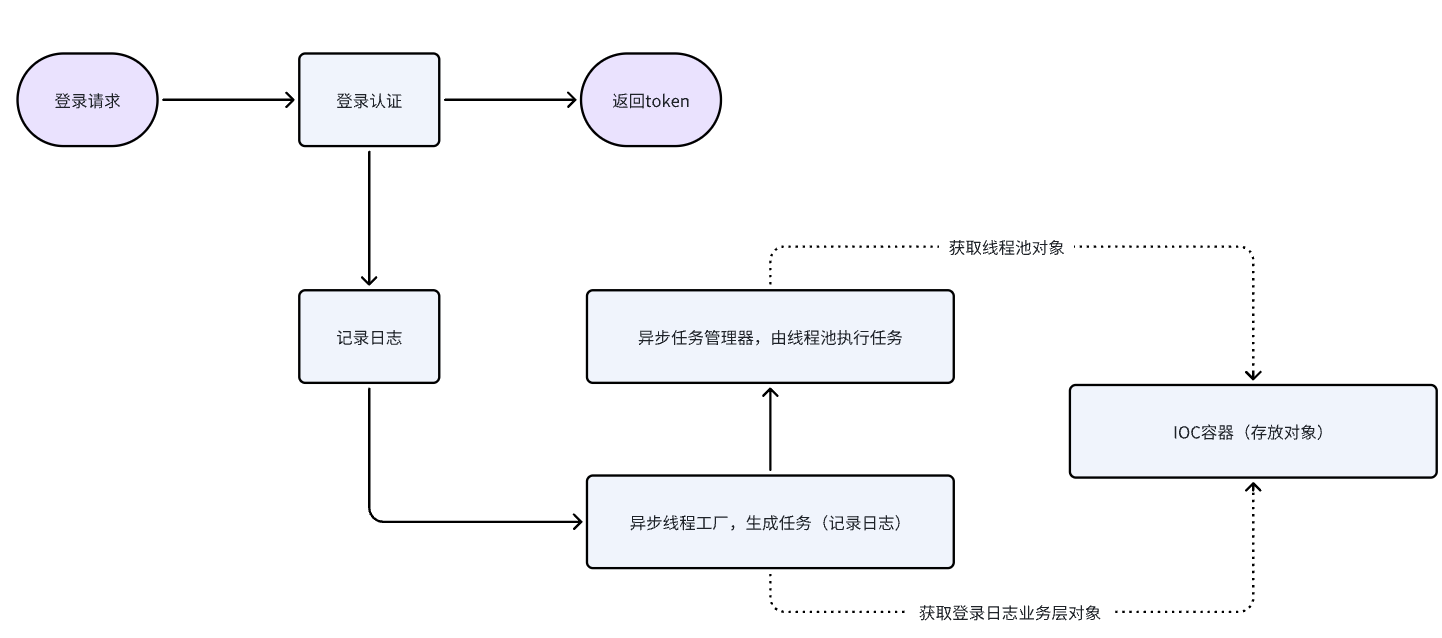

```java
// 若依登录日志的调用形式，参数以工程签名为准
AsyncManager.me().execute(
    AsyncFactory.recordLogininfor(username, status, message)
);
```

| 组件 | 职责 |
|---|---|
| `AsyncFactory` | 创建 `TimerTask` 等任务，封装要执行的逻辑 |
| `AsyncManager` | 从容器获取执行器，统一提交/管理任务 |
| `ScheduledExecutorService` | 在池内线程执行任务，支持延迟提交 |
| 日志 Service / Mapper | 将日志写入数据库 |

使用 `TimerTask` 作为任务对象并不等于只用单线程 `Timer`，实际并发由提交它的执行器决定。任务工厂与管理器分工，便于复用提交策略。

**补充/改进**：任务与主请求仍共享进程和部分资源。异步降低等待，并不保证日志不丢或彻底隔离故障；进程关闭、队列积压或数据库故障仍会影响结果。必须确保成功的后台任务可考虑持久化消息、重试和幂等。


## 异步任务中的上下文与生命周期

异步线程执行时，HTTP 请求可能已经结束，当前用户通常保存在主线程的 `ThreadLocal` 中，不能假定新线程自动拥有它。

**整理示例**：提交前把用户名、用户 ID、部门 ID 和必要请求信息复制为不可变快照，再传给任务；后台任务只读取自己的参数，不继续引用可变请求对象。

```java
Long userId = loginUser.getUserId();
Long deptId = loginUser.getDeptId();
String userName = loginUser.getUsername();
executor.execute(() -> logService.save(userId, deptId, userName));
```

`executor` 由容器管理。工程应明确异常记录、容量和停机策略，监测任务拒绝、排队时间和失败数。事务内启动异步任务还可能在提交前读取不到新数据，需要在提交后触发或通过事件/消息解耦。


## 操作日志：@Log 的参数与用途

后台关键操作需要记录“谁在什么时候做了什么，是否成功”。每个接口手写日志会重复且容易漏记，若依用 `@Log` 标记需记录的方法。

```java
@Log(title = "订单管理", businessType = BusinessType.INSERT)
public AjaxResult add(Order order) {
    return toAjax(orderService.insertOrder(order));
}
```

| 参数 | 类型 / 默认值 | 作用 |
|---|---|---|
| `title` | String / 空 | 操作模块 |
| `businessType` | BusinessType / OTHER | INSERT、UPDATE、DELETE、GRANT、EXPORT、IMPORT、FORCE、GENCODE、CLEAN 等 |
| `operatorType` | OperatorType / MANAGE | OTHER、后台 MANAGE、手机端 MOBILE |
| `isSaveRequestData` | boolean / true | 是否保存请求参数 |
| `isSaveResponseData` | boolean / true | 是否保存响应参数 |
| `excludeParamNames` | String[] / 空数组 | 排除指定请求参数 |

登录日志记录认证事件，操作日志记录业务动作，两者的对象和表不同，不能只看其中一种来追溯全部行为。


## LogAspect：收集信息后异步落库

**课件链路**：请求调用带 `@Log` 的 Controller 方法，AOP 切面读取注解及操作人、模块、类型等信息，构造异步日志任务，最后由线程池调用日志 Service 落库。

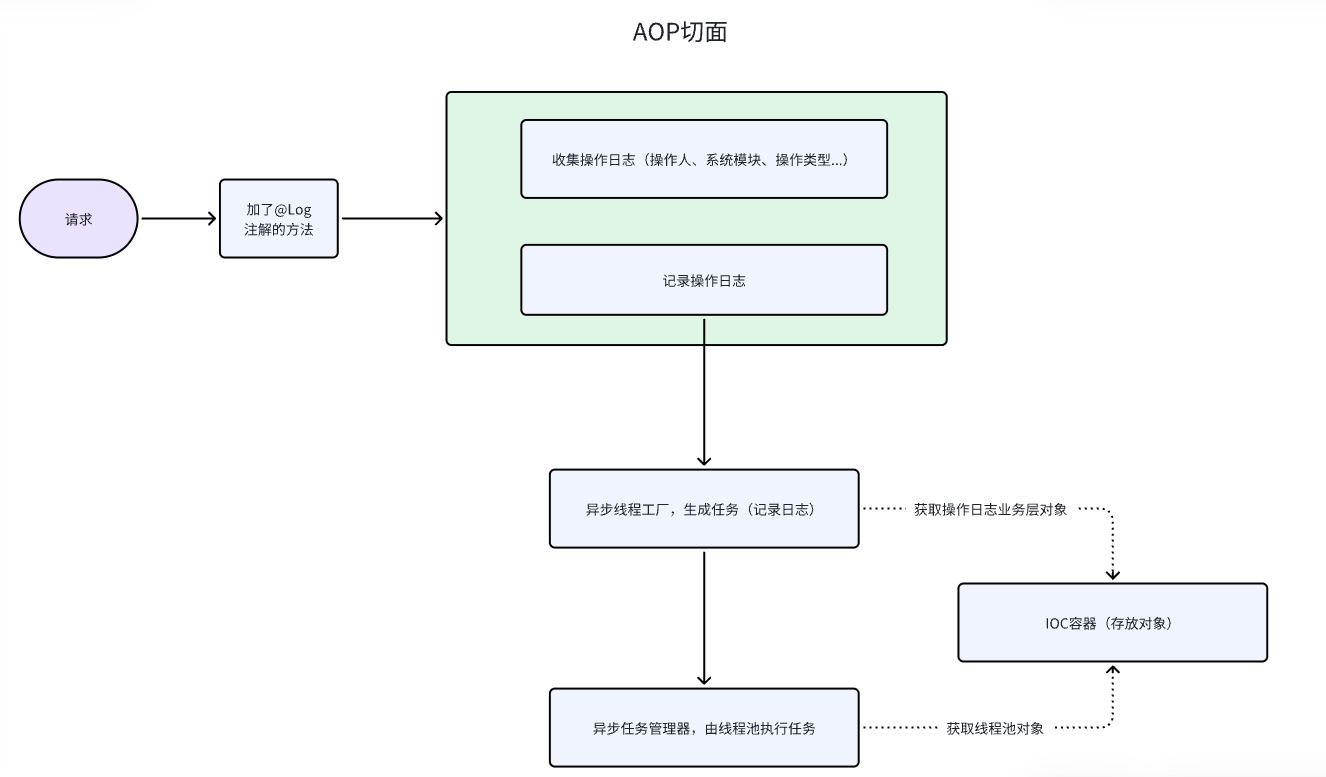

AOP（面向切面编程）将日志这种横跨多个业务方法的逻辑集中处理。成功返回和异常分支都需要记录，异常日志应保留错误信息；业务方法不必自己重复写日志代码。

**补充/改进示例**：

```java
@Log(title = "密码重置", businessType = BusinessType.UPDATE,
     isSaveResponseData = false,
     excludeParamNames = {"password", "oldPassword", "newPassword"})
```

排除请求字段不自动隐藏响应中的敏感数据。日志内容还应考虑 Token、个人信息、超长对象和文件上传，必要时关闭响应保存或先脱敏。


## 定时任务：业务配置与执行日志

若依后台支持动态添加、修改、暂停、恢复和删除任务。相比写死在注解里的计划，运营人员可通过 Web 页面调整任务。

| 表 | 关键字段 | 用途 |
|---|---|---|
| `sys_job` | `job_id`、`job_name`、`job_group`、`invoke_target`、`cron_expression` | 保存业务任务和调用目标 |
| `sys_job` | `misfire_policy`、`concurrent`、`status` | 错过执行时间的策略、是否并发、当前状态 |
| `sys_job_log` | `job_log_id`、`job_message`、`status`、`exception_info`、`create_time` | 保存任务运行结果和异常 |

课件 `status` 为 `0=正常、1=暂停`；`concurrent` 为 `0=允许、1=禁止`。这些值与第二篇工单状态或设备状态不同，不能混用字典。

定时任务模块是 `dkd-quartz`，包含配置、三层业务代码、`task` 示例及 `util` 工具。前端入口为 `api/monitor/job.js` 和 `views/monitor/job/`。


## Quartz 核心 API：任务、触发器和调度器

Quartz 把“做什么”和“何时做”分开，调度器将两者关联。

| API | 作用 |
|---|---|
| `Job` | 实际执行的任务类，实现 `execute(...)` |
| `JobDetail` | 任务定义，包括 Job 类、名称、组和数据；不是正在运行的 Job 实例 |
| `JobBuilder` | 构造 JobDetail |
| `Trigger` | 触发执行的规则 |
| `SimpleTrigger` | 简单重复规则，如固定间隔 |
| `CronTrigger` | 使用 Cron 表达式的复杂日历规则 |
| `TriggerBuilder` | 构造触发器 |
| `Scheduler` | 管理注册、启动、暂停、恢复、删除等调度行为 |

```text
JobDetail（做什么） + Trigger（什么时候）
                       ↓
                  Scheduler
                       ↓
                   Job.execute
```

**课件修正**：第 63 页将 JobDetail 简写为“包括 Job 实例”。准确地说，它持有任务定义和 Job 类等信息，任务执行实例由 Quartz 的 JobFactory 创建。


## 任务初始化与运行链路

课件 `SysJobServiceImpl` 在初始化时清理调度器，读取 `sys_job`，再逐个注册：

```java
@PostConstruct
public void init() throws SchedulerException, TaskException {
    scheduler.clear();
    List<SysJob> jobList = jobMapper.selectJobAll();
    for (SysJob job : jobList) {
        ScheduleUtils.createScheduleJob(scheduler, job);
    }
}
```

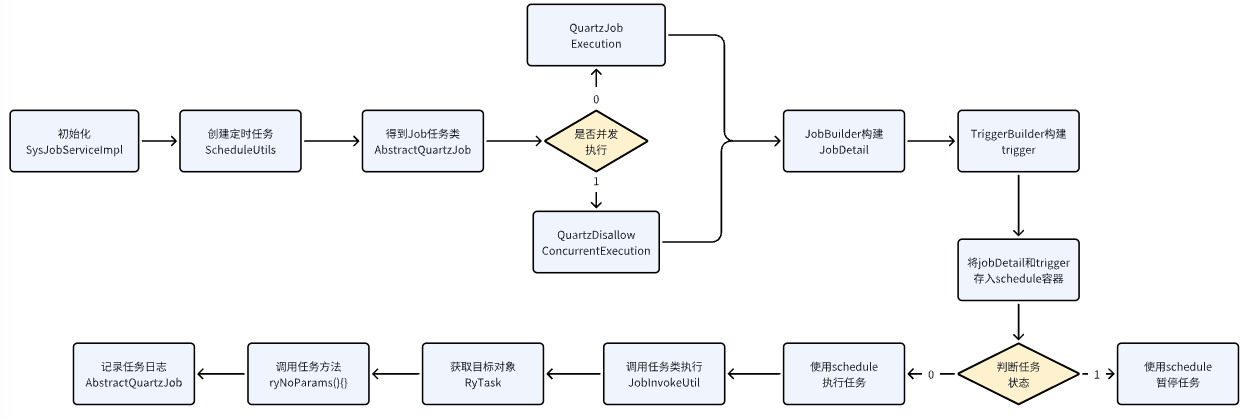

`ScheduleUtils` 根据并发配置选择 `QuartzJobExecution` 或 `QuartzDisallowConcurrentExecution`，用 Builder 构造 JobDetail 和 Trigger，注册进 Scheduler。任务触发后，包装 Job 交给 `JobInvokeUtil` 解析调用字符串、获取目标 Bean 并调用目标方法，最后记录执行日志。

禁止并发通常通过 `@DisallowConcurrentExecution` 实现，限制的是同一 JobKey 的重叠运行，不等于全系统只能跑一个任务。

**补充/改进**：`scheduler.clear()` 会清空调度器中的全部注册对象。单机从业务表重建的演示可以如此实现；共享 JDBC 调度库时每个节点启动都清空，可能影响其他节点正在管理的任务。部署集群前必须检查并改成可协调、幂等的初始化方式。


## 新增任务、状态切换与安全校验

课件新增任务流程：校验 Cron → 校验目标字符串 → 白名单校验 → 状态初始化为暂停并保存配置 → `ScheduleUtils` 创建任务。

```text
ryTask.ryNoParams
ryTask.ryParams('ry')
```

调用字符串可指定 Bean 方法和参数。它最终进入反射调用，因此必须限制可调用类/包/方法，不能让后台输入任意代码执行目标。

状态切换先按 ID 取配置，把目标状态写入数据库，再恢复或暂停 Quartz 中的对应 Job。修改 Cron 还需更新触发规则；仅更新 `sys_job` 的字符串不会自动改变已注册 Trigger。

**怎么用**：先以暂停状态新增一个无副作用的测试任务；确认调用目标、Cron 和日志后再开启。修改后对照下一次触发时间与执行日志，确保页面配置和调度器一致。


## Cron、Misfire 和并发的区别

这些选项分别约束不同问题：

| 配置 | 回答的问题 | 例子 |
|---|---|---|
| Cron | 什么时候执行 | `0/10 * * * * ?` 每 10 秒触发 |
| Misfire | 计划时间已错过怎么办 | 跳过错过的执行、立即补一次等 |
| 禁止并发 | 上一次还没结束时怎么办 | 同一任务不重叠运行 |

Quartz Cron 通常有 6 个字段（秒、分、时、日、月、周），年可选。`?` 只用于日或周字段，表示不指定；不能直接套用 Linux 的五字段 crontab。

**补充/改进**：禁止并发不能替代业务幂等。任务在故障恢复、人工重试或网络异常后可能再次执行，发短信、结算、库存同步等操作仍应使用业务唯一标识避免重复生效。


## Quartz 集群：共享存储与节点协调

如果多个应用实例都按自己的内存计划执行同一任务，可能重复执行。课件集群方案通过共享数据库持久化任务与触发器，利用锁和节点状态协调执行。

| 模式 | 存储和协调 | 适用 |
|---|---|---|
| RAMJobStore | 任务定义和触发器在本进程内存 | 单节点、允许重建计划 |
| JDBC JobStore 集群 | 节点共享 Quartz 表、协调触发器获取 | 高可用、分担任务执行 |

课件步骤：导入 `quartz.sql` → 启用 `ScheduleConfig` 集群配置 → 复制启动节点（示例用另一个端口）。**补充核对项**：各节点指向同一调度库、启用集群、使用同一逻辑 Scheduler 名称和不同实例 ID，时钟同步，并审查初始化清空行为。

同一次正常触发由节点协调领取；多节点部署不意味着每个节点都执行一遍，也不提供业务“绝不重复”保证。重试、恢复和外部系统交互仍需幂等。


## Quartz 集群的 11 张表

`sys_job` 是若依的业务任务配置，`qrtz_*` 是 Quartz 引擎维护的调度状态。两类表都存在，职责不同。

| 表 | 准确用途 |
|---|---|
| `qrtz_job_details` | Job 定义、类名及任务数据 |
| `qrtz_triggers` | 所有触发器的基础信息、状态及触发时间 |
| `qrtz_cron_triggers` | Cron 表达式和时区等特定信息 |
| `qrtz_simple_triggers` | 重复次数、间隔、已触发次数 |
| `qrtz_blob_triggers` | 以二进制形式保存其他触发器信息 |
| `qrtz_simprop_triggers` | 用简单属性列持久化的触发器扩展信息 |
| `qrtz_scheduler_state` | 集群实例的心跳和检查时间 |
| `qrtz_locks` | 数据库锁，用于协调调度操作 |
| `qrtz_paused_trigger_grps` | 已暂停的触发器组 |
| `qrtz_fired_triggers` | 已获取、正在执行的触发记录及所属实例 |
| `qrtz_calendars` | 额外日历约束，例如排除节假日 |

**课件修正**：`qrtz_scheduler_state` 不用于维护一个固定“主节点”；`qrtz_fired_triggers` 也不是长期完整执行历史。审计和任务结果应查看 `sys_job_log` 或专门监控记录。


## 数据权限的五种范围

拿到“用户列表”权限后，普通人员也不应自动看到所有公司的用户。若依将数据范围配置在角色上，按用户关联角色计算可见记录。

| `data_scope` | 范围 | 常见过滤逻辑 |
|---|---|---|
| `1` | 全部数据 | 不添加范围限制 |
| `2` | 自定义数据 | 部门在 `sys_role_dept` 指定范围内 |
| `3` | 本部门数据 | 部门 ID 等于当前用户部门 |
| `4` | 本部门及以下数据 | 当前部门及其子部门 |
| `5` | 仅本人数据 | 记录用户 ID 等于当前用户 ID |

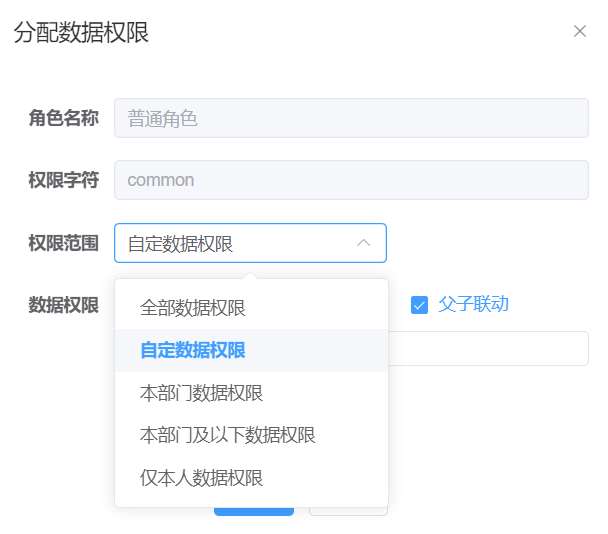

课件默认超级管理员 `userId=1` 拥有全部范围。普通角色选择“全部数据”也可以不受范围过滤，这属于角色配置而非管理员身份。

**正反例**：分公司负责人只能看本公司及下级部门，部门员工只能看本人记录；若只配置菜单权限，二者调用同一列表接口就可能返回相同的全部数据。


## 数据权限的表关系

范围计算需要用户身份、用户所属部门、用户角色和角色范围四类信息。

```text
sys_user ── sys_user_role ── sys_role（data_scope）
   │                           │
 dept_id                  sys_role_dept（自定义范围）
   │                           │
   └──────── sys_dept ─────────┘
              parent_id / ancestors
```

`sys_dept.ancestors` 保存部门祖先路径，用于找当前部门的下级部门；`sys_role_dept` 保存自定义选择的部门，不负责菜单权限。菜单关联使用 `sys_role_menu`。

同一用户可能有多个角色，常见若依实现将适用角色的范围按并集组合，有“全部”时不再限制。具体还需检查版本是否根据当前权限标识筛选角色；不能把所有角色的范围无条件套到每个业务接口。


## @DataScope 与 Mapper XML 的配合

若依使用自定义注解告诉切面 SQL 中的部门别名和用户别名，再通过实体的 `params` 传递生成的条件。

```java
@DataScope(deptAlias = "d", userAlias = "u")
public List<SysUser> selectUserList(SysUser query) {
    return userMapper.selectUserList(query);
}
```

**整理示例**：

```xml
<select id="selectUserList" parameterType="SysUser" resultMap="UserResult">
  SELECT u.user_id, u.user_name, u.dept_id
  FROM sys_user u
  LEFT JOIN sys_dept d ON d.dept_id = u.dept_id
  <where>
    <!-- 其他业务查询条件 -->
    ${params.dataScope}
  </where>
</select>
```

条件对象继承 `BaseEntity`，其中 `params` 能携带范围文本；SQL 别名必须与注解一致，实际查询必须能访问所用部门/用户 ID。课件第 81 页的 `${params.datasScope}` 是拼写错误，正确键是 **`dataScope`**。

**课件边界**：“业务表必须有 `dept_id`、`user_id`”是直接按本表归属字段过滤的实现条件。如果通过关联表取得所属部门和用户，也可在对应别名上过滤；关键是查询可表达归属关系。


## DataScopeAspect 的执行过程

仅加注解不会改变查询结果，必须经过 Spring AOP 代理并在 SQL 中接入过滤条件。

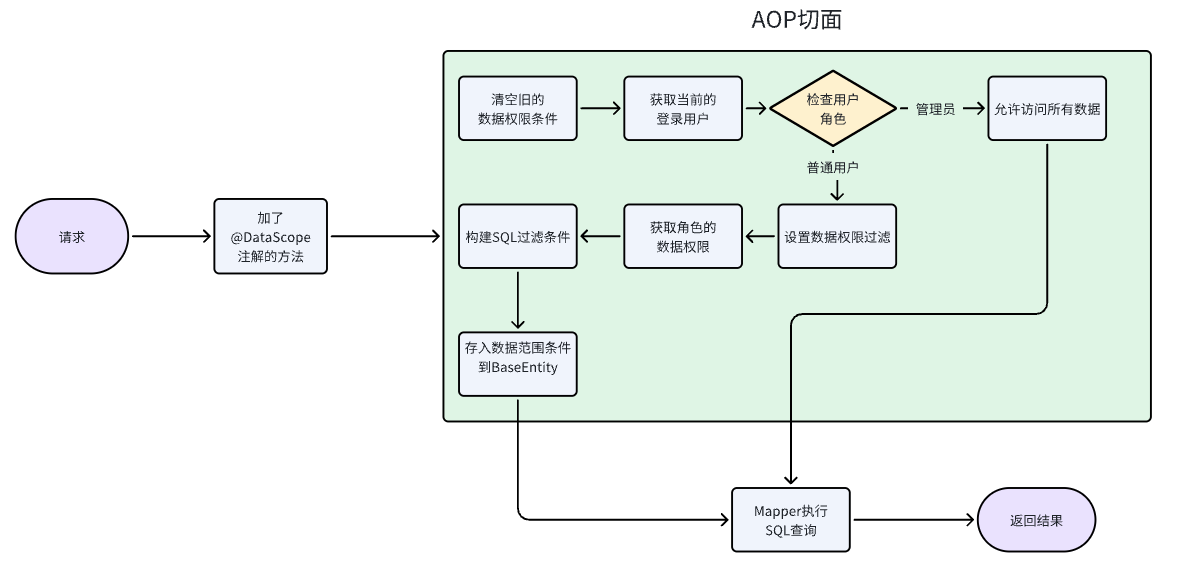

```text
进入带 @DataScope 的 Service 方法
  → 清空旧 params.dataScope
  → 获取当前登录用户
  → 管理员直接放行
  → 普通用户读取适用角色及 data_scope
  → 生成部门/本人过滤 SQL
  → 将条件写入 BaseEntity.params
  → Mapper 插入该条件，数据库执行受限查询
```

清空旧值既避免条件复用污染，也防止前端提交伪造 `params.dataScope`。方法内部 `this.xxx()` 自调用通常绕过 Spring 代理，因此不能假定内层注解也生效。

**面试提示**：如果接口仍返回全部数据，顺序检查是否走代理、参数是否兼容切面、数据范围是否为空、Mapper 是否拼接条件、表别名是否正确。不要直接在前端过滤结果，敏感数据已经传出。


## ${} 拼接的信任边界与覆盖范围

MyBatis 的 `#{}` 产生绑定参数，`${}` 直接插入文本。数据权限需要拼接一个完整 SQL 条件，所以课件使用 `${params.dataScope}`。

> SQL 片段只能由服务端可信权限逻辑构造，并在查询前清空外部传入值。不能把浏览器提交的 dataScope 原样插入 SQL。

| 内容 | 处理方式 |
|---|---|
| 姓名、状态、ID 等普通值 | 使用 `#{}` 绑定 |
| 注解里的表别名 | 服务端固定定义，不由请求提供 |
| 数据范围 SQL | 切面依据可信身份/角色生成 |
| 用户要求的排序字段 | 服务端白名单映射 |

**补充/改进**：列表、导出、详情、批量操作都应使用同一授权边界。列表被过滤后，`getById`、删除或导出若仍能绕过范围，就可能越权。组织数据权限也不是完整的多租户隔离方案，租户 ID 和跨租户写入还需要专门约束。

无适用角色或无可见部门时，应验证查询返回空范围，而不是因条件为空意外放行；这是权限改造必须覆盖的异常分支。


## 登录日志的数据权限改造

**课件需求**：`sys_logininfor` 默认保存全体用户登录事件，但各角色不应看到全部日志。改造顺序是权限注解、表字段、实体属性、映射文件、异步工厂。

1. 在日志查询 Service 方法添加 `@DataScope(deptAlias = "d", userAlias = "u")`。
2. 在 `sys_logininfor` 增加 `dept_id`、`user_id`。
3. `SysLogininfor` 继承 `BaseEntity`，新增对应属性及访问方法。
4. XML 的 SELECT、resultMap、INSERT 对齐新增字段，查询中提供 `d`、`u` 别名及范围条件。
5. 在 `AsyncFactory.recordLogininfor` 中填充归属字段，日志插入时持久化。

**整理示例查询骨架**：

```sql
SELECT u.info_id, u.user_name, u.user_id, u.dept_id, u.login_time
FROM sys_logininfor u
LEFT JOIN sys_dept d ON d.dept_id = u.dept_id
-- XML 的 <where> 中继续拼接服务端生成的 params.dataScope
```

这里 `u` 指日志表而不是用户表，因为本人范围应过滤记录中的 `user_id`。截图只展示 `${params.dataScope}` 放入 `<where>`，完整查询还需要补齐与注解一致的别名。


## 异步登录日志的归属信息与空值处理

课件第 86 页通过用户名查询用户，再填充日志归属：

```java
SysUser user = SpringUtils.getBean(ISysUserService.class)
        .selectUserByUserName(username);
logininfor.setUserId(user.getUserId());
logininfor.setDeptId(user.getDeptId());
```

**补充/改进**：错误用户名也要记录失败登录，但该查询可能返回 null。直接解引用会使异步日志失败，导致最需要追踪的失败记录丢失。

```java
// 整理示例：不抛空指针，保留未知账号的失败事件
if (user != null) {
    logininfor.setUserId(user.getUserId());
    logininfor.setDeptId(user.getDeptId());
}
logininforService.insertLogininfor(logininfor);
```

未知账号日志由管理员或专门安全角色查看，不能为方便展示赋予任意部门归属。历史日志没有新字段时也要制定回填/可见性策略；仅用当前用户名回填未必还原当时身份。

成功认证后优先在提交任务前携带可信用户/部门快照，避免用户名改名、账号删除或员工调动发生在异步执行前。还需确定“按当时所属部门”还是“按现在所属部门”授权，两种规则会产生不同的历史日志可见范围。


## 源码阅读与联调验证路线

本文以课件为来源整理机制；下面是学习时可执行的验证步骤，不代表已运行项目。

| 主线 | 核对方式 |
|---|---|
| 生成器 | 导入样例表，调整字典和查询方式，预览/生成，编译并检查文件路径 |
| 功能权限 | 用管理员和普通角色对比菜单及按钮，再直接请求受限接口验证拒绝 |
| 异步日志 | 观察响应时间与日志写入时机，测试后台异常是否可观测 |
| 操作日志 | 对新增成功和失败各调用一次，检查操作者、结果及敏感字段 |
| 定时任务 | 暂停状态新增，启用、修改 Cron、暂停，核对调度及日志 |
| 集群 | 两节点共用调度库，检查实例 ID、任务协调与节点重启行为 |
| 数据权限 | 为五种范围准备可辨识数据，检查列表、详情、导出及异步日志 |

让 AI 协助分析时提供真实方法、Mapper XML、角色配置和实际请求/响应，要求它输出调用链与可验证条件。只有类名和一句报错，模型难以判断权限在哪一层丢失。


## 高频面试提示

**面试提示**：本篇最关键的是分清责任边界：生成器是“元信息 + 配置 + 模板”的渲染工具；认证确定身份，授权控制功能，数据权限约束记录；异步减少主线程等待但不保证任务可靠；AOP 将日志和范围计算集中到切面；Quartz 的 JobDetail 定义任务、Trigger 定义时机、Scheduler 协调执行；集群持久化协调不能替代业务幂等。能沿着页面、Controller、Service、切面、Mapper 和数据库说明一次真实请求，就能把“使用若依”提升到“理解并修改若依”。
